<a href="https://colab.research.google.com/github/thefeufollet/ichiban/blob/main/BINF761_CMD_FinalProjectTB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import packages

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import torch
import torch.nn as nn
import torch.optim as optim
import umap
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Load TB excel data
df = pd.read_excel('TB_Samples.xlsx')

# Convert to CSV
df.to_csv('TB_Samples.csv', index=False)

In [ ]:
# Load data for model
data_path = 'TB_Samples.csv'

try:
    df_genomic = pd.read_csv(data_path)
    print("Dataset loaded successfully!")
    display(df_genomic.head())
    print("\nDataFrame Info:")
    df_genomic.info()
except FileNotFoundError:
    print(f"Error: The file '{data_path}' was not found. Please ensure the path is correct.")
except Exception as e:
    print(f"Error: {e}")

Dataset loaded successfully!


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28
0,Sample Name (identifiers represent unique labe...,Accession Number,Year,Regione,"Country of origine (Italian0, Foriegn born 1)","Pulmonary (0), Extrapulmonary (1)","HIV (0,No),(1,Yes)",Total.Reads,Mapped Reads to MTBC genome,% Mapped Reads to MTBC genome,...,EMB,PZA,INH (0.4 mg/L),AMK,MOXI (0.25 mg/L),ETH,LZD,CFZ,DLM,BDQ
1,2017FPG002,SRR31011455,2017,Lazio,Not available,1,Not available,2423290,2378139,98.14,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2017FPG003,SRR31011454,2017,Lazio,Not available,0,1,3092887,3075359,99.43,...,S,S,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2017FPG006,SRR31011409,2017,Lazio,Not available,0,Not available,2713949,2705233,99.68,...,S,R,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2017FPG009,SRR31011398,2017,Lazio,Not available,0,Not available,2761324,2746370,99.46,...,S,S,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2521 entries, 0 to 2520
Data columns (total 29 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   Unnamed: 0                              2521 non-null   object
 1   Unnamed: 1                              2521 non-null   object
 2   Unnamed: 2                              2521 non-null   object
 3   Unnamed: 3                              2521 non-null   object
 4   Unnamed: 4                              2521 non-null   object
 5   Unnamed: 5                              2521 non-null   object
 6   Unnamed: 6                              2521 non-null   object
 7   Unnamed: 7                              2521 non-null   object
 8   Unnamed: 8                              2521 non-null   object
 9   Unnamed: 9                              2521 non-null   object
 10  Unnamed: 10                             2521 non-null  

In [ ]:
# EDA: Missing Values
missing_values = df_genomic.isnull().sum()
missing_values = missing_values[missing_values > 0]

if missing_values.empty:
  print("No Missing Values")
else:
  print("Missing")
  display(missing_values.sort_values(ascending=False))

Missing


,0
Unnamed: 26,2518
Unnamed: 27,2514
Unnamed: 28,2514
Unnamed: 21,2502
Unnamed: 25,2491
Unnamed: 23,2488
Unnamed: 24,2486
Unnamed: 22,2480
Unnamed: 13,2145
Unnamed: 20,171


In [43]:
# Normalization:

# 1 Clean DF:
df_cleaned = df_genomic.copy()

# Extract Header Names:
new_column_names = [str(col).strip() for col in df_cleaned.iloc[0].values]

df_cleaned.columns = new_column_names
print("Cleaned DF Columns", df_cleaned.columns.tolist())

# 2 Target Var y:
y = df_cleaned['Drug Resistance Type']

columns_to_drop = ['Sample Name (identifiers represent unique labels...)',
    'Accession Number',
    'Year',
    'Regione',
    'Province',
    'Type',
    'Sub-Lineage',
    'Collection date (MM-DD-YYYY)',
    'Collection date (YYYY)',
    'MIRU-VNTR',
    'GenoTypeMTBC result',
    'Phenotypic drug susceptibility testing',
    'lineage', # corrected to lowercase 'lineage' after troubleshooting
    'lineage_name',
    'Drug Resistance Type']

columns_to_drop_existing = [columns for columns in columns_to_drop if columns in df_cleaned.columns]

X = df_cleaned.drop(columns=columns_to_drop_existing, errors='ignore')

# 3 Numeric Conversion:
for columns in X.columns:
  X[columns] = pd.to_numeric(X[columns], errors='coerce')

# Determine info before dropping NaNs:
print(f"\nshape of X before NaN handling: {X.shape}")
print("NaN Values Vefore Imputation")
display(X.isnull().sum()[X.isnull().sum() > 0])

#4 Missing Values / NaNs: Drop NaNs
X = X.dropna(axis=1, how='all')
# Impute rest of NaNs w/ mean of resp. column:
X = X.fillna(X.mean(numeric_only=True))

# Drop from target var y and Alignment:
initial_X_index = X.index
initial_y_index = y.index

#Drop rows from X w/ NaN:
X = X.dropna()
# Align y w/ X
y = y.loc[X.index]

print(f"\nShape of X After NaN Removal & Alignment: {X.shape}")
print("Final Number of NaNs") # should be zero
display(X.isnull().sum()[X.isnull().sum() > 0])

Cleaned DF Columns ['Sample Name (identifiers represent unique labels assigned by the different collaborating centers involved in the study)', 'Accession Number', 'Year', 'Regione', 'Country of origine (Italian0, Foriegn born 1)', 'Pulmonary (0), Extrapulmonary (1)', 'HIV (0,No),(1,Yes)', 'Total.Reads', 'Mapped Reads to MTBC genome', '% Mapped Reads to MTBC genome', 'Median Coverage', 'Uncovered (Missing Nucleotides)', 'Drug Resistance Type', 'Drug.Resistance.Variants', 'lineage', 'lineage_name', 'Cluster ( 5 SNP threshold)', 'INH (0.1 mg/L)', 'RIF', 'EMB', 'PZA', 'INH (0.4 mg/L)', 'AMK', 'MOXI (0.25 mg/L)', 'ETH', 'LZD', 'CFZ', 'DLM', 'BDQ']

shape of X before NaN handling: (2521, 23)
NaN Values Vefore Imputation


,0
Sample Name (identifiers represent unique labels assigned by the different collaborating centers involved in the study),2521
"Country of origine (Italian0, Foriegn born 1)",456
"Pulmonary (0), Extrapulmonary (1)",256
"HIV (0,No),(1,Yes)",1555
Total.Reads,1
Mapped Reads to MTBC genome,1
% Mapped Reads to MTBC genome,1
Median Coverage,1
Uncovered (Missing Nucleotides),5
Drug.Resistance.Variants,2521



Shape of X After NaN Removal & Alignment: (2521, 8)
Final Number of NaNs


,0


In [44]:
# Encode Labels:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y = pd.Series(y_encoded, index=y.index)

# Train / Test Split:

X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Fit Scaler to Training Data:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Scale X with Fitted Scaler:
X_scaled_full = scaler.transform(X)
df_genomic_scaled = pd.DataFrame(X_scaled_full, columns=X.columns)

# Print Head & Summary Stats:
print("First 5 Rows of Scaled Features")
display(df_genomic_scaled.head())
print("\nDescriptive Statistics of Normalized Features:")
display(df_genomic_scaled.describe())

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

First 5 Rows of Scaled Features


,"Country of origine (Italian0, Foriegn born 1)","Pulmonary (0), Extrapulmonary (1)","HIV (0,No),(1,Yes)",Total.Reads,Mapped Reads to MTBC genome,% Mapped Reads to MTBC genome,Median Coverage,Uncovered (Missing Nucleotides)
0,0.015436,-0.001239,0.004715,0.016020,0.016577,0.006877,0.015847,0.018155
1,0.015436,2.226492,0.004715,-0.440186,-0.400890,0.216657,0.446558,0.181864
2,0.015436,-0.500974,6.267751,-0.039667,0.033933,0.362051,1.104575,0.125941
3,0.015436,-0.500974,0.004715,-0.266329,-0.196897,0.390228,0.765597,-0.504766
4,0.015436,-0.500974,0.004715,-0.237991,-0.171242,0.365432,0.925116,0.721635



Descriptive Statistics of Normalized Features:


,"Country of origine (Italian0, Foriegn born 1)","Pulmonary (0), Extrapulmonary (1)","HIV (0,No),(1,Yes)",Total.Reads,Mapped Reads to MTBC genome,% Mapped Reads to MTBC genome,Median Coverage,Uncovered (Missing Nucleotides)
count,2521.000000,2521.000000,2521.000000,2521.000000,2521.000000,2521.000000,2521.000000,2521.000000
mean,0.015436,-0.001239,0.004715,0.016020,0.016577,0.006877,0.015847,0.018155
std,0.995241,1.000310,1.015511,1.050248,1.050165,0.994060,1.048678,1.027092
min,-1.545061,-0.500974,-0.424830,-1.536260,-1.528585,-9.847095,-1.527496,-1.624038
25%,-1.545061,-0.500974,-0.424830,-0.648717,-0.652839,0.159175,-0.610259,-0.645191
50%,0.790031,-0.500974,0.004715,-0.114764,-0.104097,0.253851,-0.131700,-0.284503
75%,0.790031,-0.001239,0.004715,0.407118,0.411226,0.301188,0.366798,0.349099
max,0.790031,2.226492,6.267751,14.715434,15.119312,0.391355,15.919946,6.383197


Shape of X_train: (2016, 8)
Shape of X_test: (505, 8)
Shape of y_train: (2016,)
Shape of y_test: (505,)


In [45]:
# FFNN Model:
# Convert Arrays to Tensors for PyTorch:
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

# Number of Input Features:
imput_dimensions = X_train_tensor.shape[1]

# Output dimensions:
output_dimensions = int(y_train_tensor.max().item()) + 1

# FFNN:
class FeedforwardNet(nn.Module):
  def __init__(self, input_dimensions, hidden_dim1, hidden_dim2, output_dimensions):
    super(FeedforwardNet, self).__init__()
    self.fc1 = nn.Linear(input_dimensions, hidden_dim1)
    # Regularization:
    self.dropout1 = nn.Dropout(0.3)
    self.relu1 = nn.ReLU()
    self.fc2 = nn.Linear(hidden_dim1, hidden_dim2)
    self.relu2 = nn.ReLU()
    self.fc3 = nn.Linear(hidden_dim2, output_dimensions)

  def forward(self, x):
    out = self.fc1(x)
    out = self.relu1(out)
    out = self.fc2(out)
    out = self.relu2(out)
    out = self.fc3(out)
    return out

# Hyperparameters:
hidden_dim1=256
hidden_dim2=128

# Initiate Model:
model = FeedforwardNet(imput_dimensions, hidden_dim1, hidden_dim2, output_dimensions)

Starting Training:
Epoch [10/100], Loss: 1.21068274974823:.4f
Epoch [20/100], Loss: 0.8664175868034363:.4f
Epoch [30/100], Loss: 0.7481836080551147:.4f
Epoch [40/100], Loss: 0.704373300075531:.4f
Epoch [50/100], Loss: 0.6762078404426575:.4f
Epoch [60/100], Loss: 0.6606277227401733:.4f
Epoch [70/100], Loss: 0.6491487622261047:.4f
Epoch [80/100], Loss: 0.6394956111907959:.4f
Epoch [90/100], Loss: 0.6315863132476807:.4f
Epoch [100/100], Loss: 0.6247637867927551:.4f
Training Done!


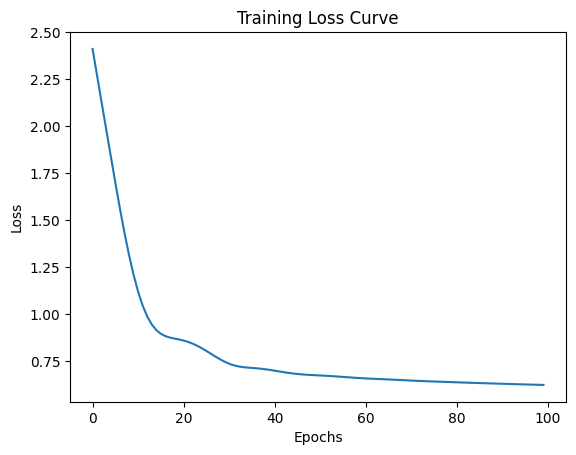

In [46]:
# Define Loss Function:

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

num_epochs = 100

print("Starting Training:")

losses = []

# Training Loop:
for epoch in range(num_epochs):
  # Forward Pass
  outputs = model(X_train_tensor)
  loss = criterion(outputs, y_train_tensor)

  # Bakcward Pass & Optimize:
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  losses.append(loss.item())

  if(epoch+1) % 10 == 0:
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item()}:.4f')

print("Training Done!")


# Loss Curve
plt.plot(losses)
plt.title("Training Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

In [ ]:
# Evaluation on Test Set
model.eval()
with torch.no_grad():
  test_outputs = model(X_test_tensor)
  _, predicted = torch.max(test_outputs.data, 1)
  accuracy = (predicted == y_test_tensor).sum().item() / y_test_tensor.size(0)
  print(f'Test Accuracy: {accuracy:.4f}')

# Confusion Matrix/F1
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, predicted.numpy()))

Test Accuracy: 0.8554
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         7
           4       0.00      0.00      0.00        10
           5       0.00      0.00      0.00        16
           6       0.00      0.00      0.00         2
           7       0.78      0.22      0.34        32
           8       0.86      1.00      0.92       427
           9       0.00      0.00      0.00         5
          10       0.00      0.00      0.00         1
          11       0.00      0.00      0.00         5

    accuracy                           0.86       505
   macro avg       0.18      0.13      0.14       505
weighted avg       0.77      0.86      0.80       505



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


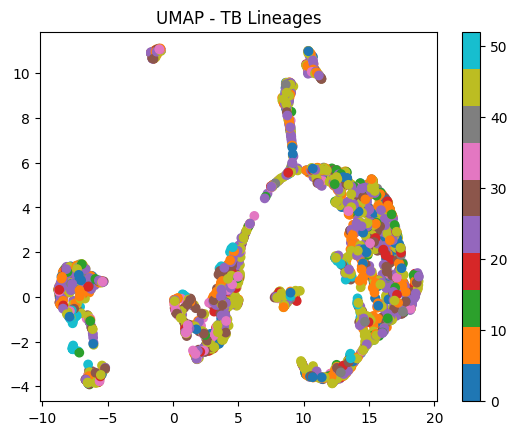

In [ ]:
# UMAP: Dimensionality Reduction and Visualization

reducer = umap.UMAP(n_components=2, random_state=42)

# Fit/Transform:
X_umap = reducer.fit_transform(X_scaled_full)
print("Shape of UMAP-reduced Data:", X_umap.shape)

# Dataframe to Plot:
df_umap = pd.DataFrame(X_umap, columns=['UMAP1', 'UMAP2'])
df_umap['label'] = y

plt.figure(figsize=(10, 8))
sns.scatterplot(x='UMAP1', y='UMAP2', hue='label', data=df_umap, palette=sns.color_palette("cubehelix", len(y.unique())), s=10, alpha=0.7, legend='full')
plt.title('UMAP Projection of Genomic Data Lineages')
plt.xlabel('UMAP1')
plt.ylabel('UMAP2')
plt.legend(title='Lineage', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.show()

In [ ]:
# Does UMAP Clusters Align with TB Lineages:
import umap.umap_ as umap

reducer = umap.UMAP()
embedding = reducer.fit_transform(X_scaled_full)

lineage_encoder = LabelEncoder()
df_cleaned['lineage_encoded'] = lineage_encoder.fit_transform(df_cleaned['lineage'].astype(str))

plt.scatter(embedding[:,0], embedding[:,1], c=df_cleaned['lineage_encoded'], cmap='tab10')
plt.title("UMAP Alignment with TB Lineages")
plt.colorbar()
plt.show()

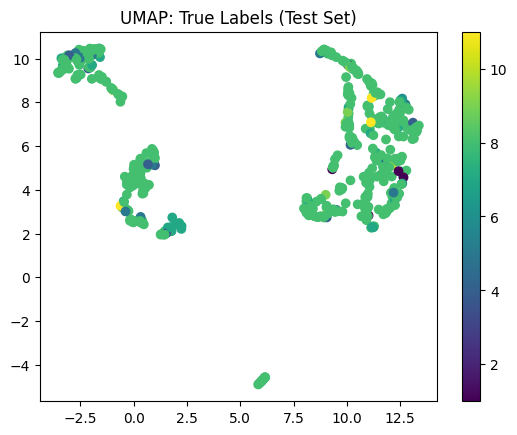

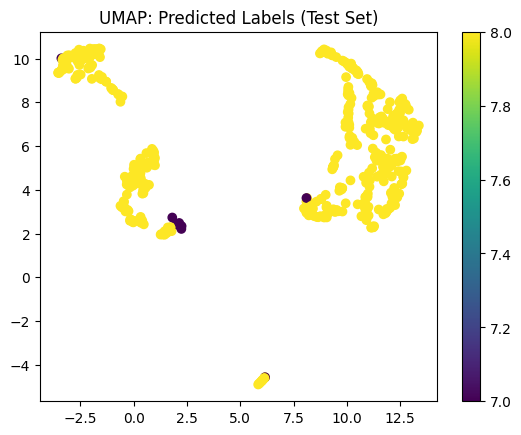

In [49]:
embedding_test = reducer.fit_transform(X_test)

# True labels
plt.scatter(embedding_test[:,0], embedding_test[:,1], c=y_test, cmap='viridis')
plt.title("UMAP: True Labels (Test Set)")
plt.colorbar()
plt.show()

# Predicted labels
plt.scatter(embedding_test[:,0], embedding_test[:,1], c=predicted.numpy(), cmap='viridis')
plt.title("UMAP: Predicted Labels (Test Set)")
plt.colorbar()
plt.show()